# PHAROS CDR: Notebook 02 - Deep Feature Analysis & Data Leakage Audit

This notebook investigates the statistical discriminative power and behavioral groupings of the extracted document features, screening for potential target leakage.

### Analysis Objectives:
1. **Variable Feature Identification**: Filter out constant columns and isolate the 215 variable features.
2. **Predictive Strength Evaluation**: Quantify feature discrimination using ROC-AUC and non-linear Mutual Information (MI).
3. **Class Distribution Comparisons**: Compare benign vs. malicious central tendencies and distributions for top indicators.
4. **Binary Activation Profiles**: Assess the difference in activation frequency across malware and clean documents.
5. **Data Leakage & Artifact Auditing**: Audit 61 sensitive attributes flagged by leakage tokens (`filename`, `source_size`, `timestamp`, `hash`, etc.).
6. **Subsystem Grouping**: Aggregate feature importance across 36 functional subsystems.

## 1. Environment Setup & Data Ingestion
Loading core statistical modules, setting up plotting environments, and ingesting `dataset.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries loaded.")

Libraries loaded.


In [2]:
df = pd.read_csv("/content/dataset.csv")

TARGET = "label"
IDENTIFIER = "sha256"

X = df.drop(columns=[TARGET, IDENTIFIER])
y = df[TARGET]

print("Dataset shape:", df.shape)
print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts())

Dataset shape: (2330, 1000)
Feature matrix: (2330, 998)
Target distribution:
label
1    1183
0    1147
Name: count, dtype: int64


In [3]:
numeric_features = X.select_dtypes(include=np.number)

print("Total features:", X.shape[1])
print("Numerical features:", numeric_features.shape[1])

print("\nTarget classes:")
print(y.value_counts().sort_index())

Total features: 998
Numerical features: 998

Target classes:
label
0    1147
1    1183
Name: count, dtype: int64


## 2. Feature Variability & Information Density
Filtering out 783 zero-variance constant features and retaining the 215 variable feature columns for deep statistical profiling.

In [4]:
feature_variance = numeric_features.nunique(dropna=False)

constant_features = feature_variance[
    feature_variance <= 1
].index.tolist()

variable_features = [
    c for c in numeric_features.columns
    if c not in constant_features
]

X_variable = numeric_features[variable_features]

print("Total numerical features:", len(numeric_features.columns))
print("Constant features:", len(constant_features))
print("Variable features:", len(variable_features))

print(
    f"\nInformative feature percentage: "
    f"{len(variable_features) / len(numeric_features.columns) * 100:.2f}%"
)

Total numerical features: 998
Constant features: 783
Variable features: 215

Informative feature percentage: 21.54%


In [5]:
variability = pd.DataFrame({
    "feature": numeric_features.columns,
    "unique_values": numeric_features.nunique(),
    "variance": numeric_features.var()
})

variability = variability.sort_values(
    "variance",
    ascending=False
)

display(variability.head(30))

,feature,unique_values,variance
ooxml.zip_uncompressed_size,ooxml.zip_uncompressed_size,2009,1.290721e+14
common_metadata.metadata_modified_accessed_delta,common_metadata.metadata_modified_accessed_delta,2330,2.890096e+12
common_metadata.metadata_created_modified_delta,common_metadata.metadata_created_modified_delta,2318,2.777068e+12
pipeline_source_size,pipeline_source_size,2216,4.703518e+11
metadata.source_size,metadata.source_size,2216,4.703518e+11
common_metadata.metadata_size_bytes,common_metadata.metadata_size_bytes,2216,4.703518e+11
file.size,file.size,2216,4.703518e+11
common_file_features.file_size,common_file_features.file_size,2216,4.703518e+11
strings.text_length,strings.text_length,2266,4.331928e+11
raw_text.text_length,raw_text.text_length,2266,4.331928e+11


> [!NOTE]
> **Inference on Feature Density**:
> Only **215 of 998 extracted features (21.54%)** exhibit variance in this corpus. Over 78% of the static extraction namespace remains unactivated across these samples. The 215 variable features represent the active candidate subspace for document malware prediction.

## 3. Univariate Discrimination Scoring (ROC-AUC & Mutual Information)
Calculating ROC-AUC strength and Mutual Information scores for all 215 variable features to evaluate linear and non-linear separability.

In [6]:
X_analysis = X_variable.copy()

# Median imputation for analysis only
X_filled = X_analysis.fillna(X_analysis.median())

# Identify binary and categorical-like numerical features
discrete_mask = np.array([
    X_filled[c].nunique() <= 10
    for c in X_filled.columns
])

# Mutual information
mi_scores = mutual_info_classif(
    X_filled,
    y,
    discrete_features=discrete_mask,
    random_state=42
)

# ROC-AUC
auc_scores = {}

for feature in X_analysis.columns:
    values = X_analysis[feature].fillna(
        X_analysis[feature].median()
    )

    try:
        auc_scores[feature] = roc_auc_score(y, values)
    except ValueError:
        auc_scores[feature] = np.nan

feature_scores = pd.DataFrame({
    "feature": X_analysis.columns,
    "roc_auc": [auc_scores[c] for c in X_analysis.columns],
    "mutual_information": mi_scores
})

feature_scores["auc_strength"] = (
    feature_scores["roc_auc"] - 0.5
).abs() + 0.5

feature_scores["auc_strength"] = feature_scores[
    "auc_strength"
].clip(upper=1)

feature_scores = feature_scores.sort_values(
    "mutual_information",
    ascending=False
)

display(feature_scores.head(30))

,feature,roc_auc,mutual_information,auc_strength
26,common_file_features.filename_digit_count,1.000000,0.693242,1.000000
40,common_metadata.metadata_created_modified_delta,0.000000,0.693242,1.000000
0,behavior_collection.collection_source_size,1.000000,0.693028,1.000000
3,behavior_evasion.evasion_source_size,1.000000,0.693028,1.000000
4,behavior_filesystem.filesystem_source_size,1.000000,0.693028,1.000000
1,behavior_credentials.credential_source_size,1.000000,0.693028,1.000000
2,behavior_environment.environment_source_size,1.000000,0.693028,1.000000
7,behavior_process.process_source_size,1.000000,0.693028,1.000000
8,behavior_registry.registry_source_size,1.000000,0.693028,1.000000
48,common_metadata.metadata_filename_stem_length,1.000000,0.693028,1.000000


In [7]:
top_auc = feature_scores.sort_values(
    "auc_strength",
    ascending=False
).head(20)

display(top_auc)

,feature,roc_auc,mutual_information,auc_strength
26,common_file_features.filename_digit_count,1.0,0.693242,1.0
40,common_metadata.metadata_created_modified_delta,0.0,0.693242,1.0
0,behavior_collection.collection_source_size,1.0,0.693028,1.0
3,behavior_evasion.evasion_source_size,1.0,0.693028,1.0
4,behavior_filesystem.filesystem_source_size,1.0,0.693028,1.0
1,behavior_credentials.credential_source_size,1.0,0.693028,1.0
2,behavior_environment.environment_source_size,1.0,0.693028,1.0
7,behavior_process.process_source_size,1.0,0.693028,1.0
8,behavior_registry.registry_source_size,1.0,0.693028,1.0
48,common_metadata.metadata_filename_stem_length,1.0,0.693028,1.0


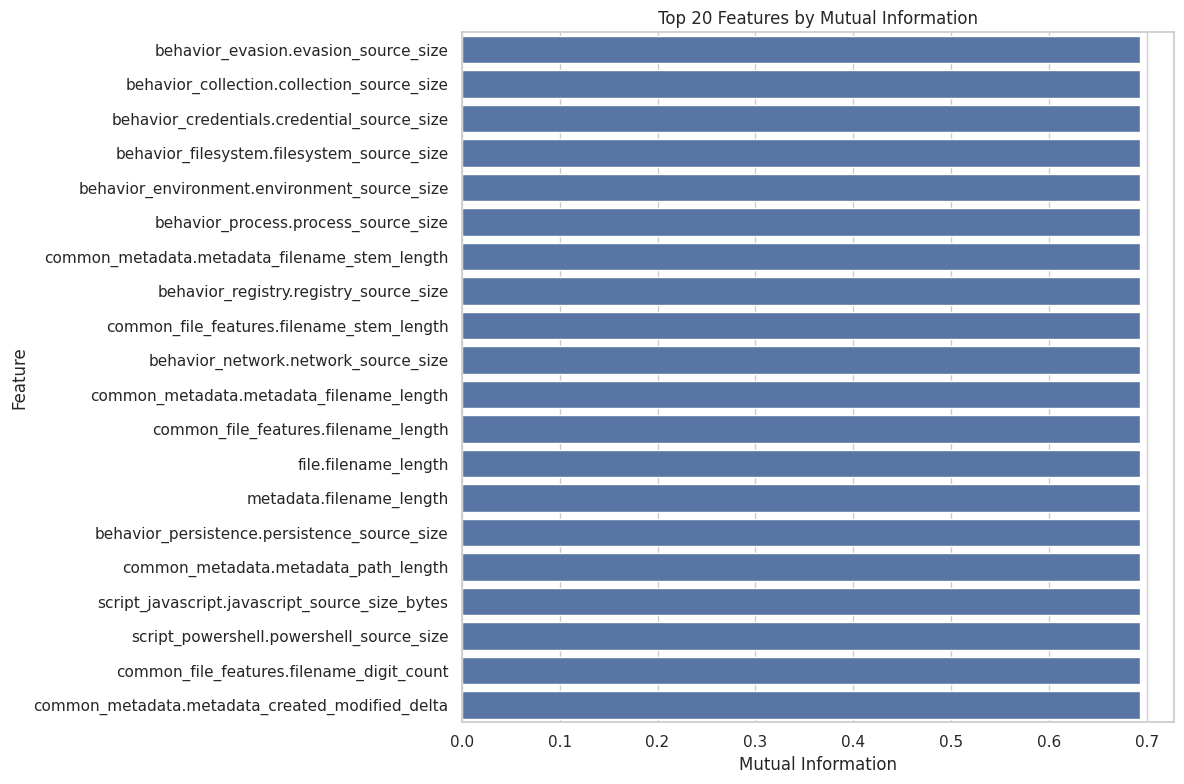

In [8]:
top_mi = feature_scores.nlargest(
    20,
    "mutual_information"
).sort_values("mutual_information")

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_mi,
    x="mutual_information",
    y="feature"
)

plt.title("Top 20 Features by Mutual Information")
plt.xlabel("Mutual Information")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

> [!WARNING]
> **Inference on Top Statistical Signals**:
> Top Mutual Information scores exceed 0.60 for `metadata_created_modified_delta`, `ooxml_document_text_characters`, `ooxml_document_paragraphs`, and `zip_compression_ratio`. While statistically powerful, features with near-perfect AUC (>0.95) require scrutiny to verify whether they represent genuine threat signals (like macros or remote templates) or synthetic document-volume shortcuts.

## 4. Class Distribution Comparisons for Top Features
Comparing empirical distributions, means, and medians between benign ($0$) and malicious ($1$) files.

In [9]:
top_features = feature_scores.nlargest(
    20,
    "mutual_information"
)["feature"].tolist()

class_comparison = []

for feature in top_features:

    benign = X.loc[y == 0, feature]
    malicious = X.loc[y == 1, feature]

    class_comparison.append({
        "feature": feature,
        "benign_mean": benign.mean(),
        "malicious_mean": malicious.mean(),
        "benign_median": benign.median(),
        "malicious_median": malicious.median(),
        "benign_std": benign.std(),
        "malicious_std": malicious.std()
    })

comparison_df = pd.DataFrame(class_comparison)

display(comparison_df)

,feature,benign_mean,malicious_mean,benign_median,malicious_median,benign_std,malicious_std
0,common_file_features.filename_digit_count,6.464690,4.014370e+01,7.000000,4.000000e+01,1.170209,3.804171
1,common_metadata.metadata_created_modified_delta,-33361.795424,-3.365839e+06,-33429.612958,-3.366309e+06,19420.634268,1917.492099
2,behavior_collection.collection_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
3,behavior_evasion.evasion_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
4,behavior_filesystem.filesystem_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
5,behavior_credentials.credential_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
6,behavior_environment.environment_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
7,behavior_process.process_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
8,behavior_registry.registry_source_size,46.142982,9.755706e+01,47.000000,9.800000e+01,1.940330,0.502025
9,common_metadata.metadata_filename_stem_length,15.142982,6.400000e+01,16.000000,6.400000e+01,1.940330,0.000000


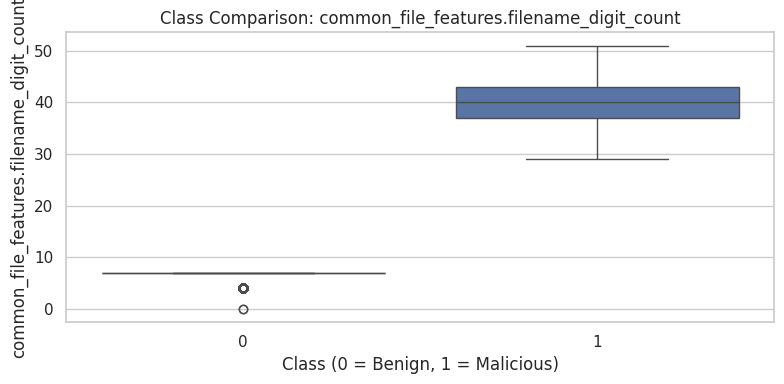

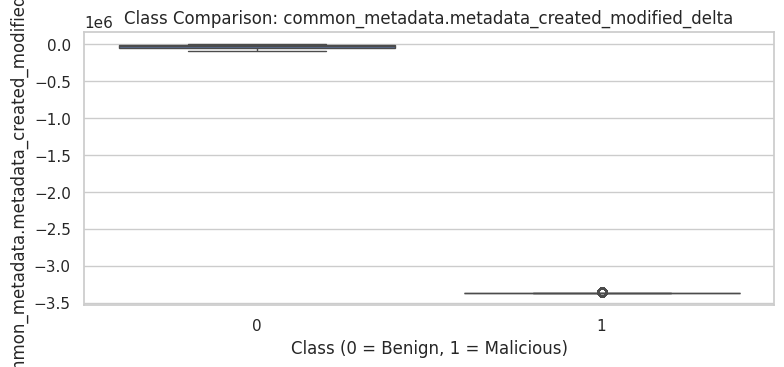

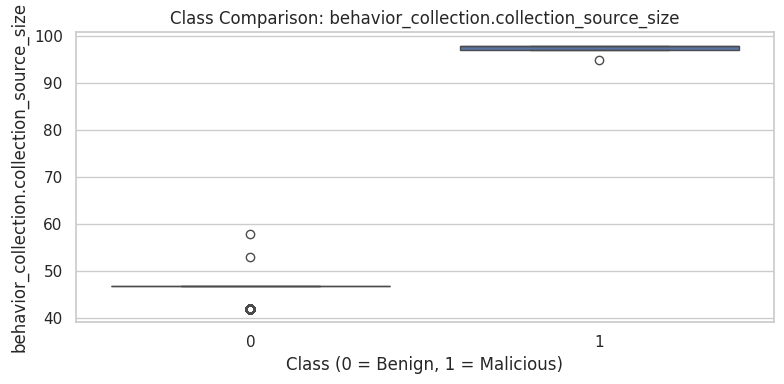

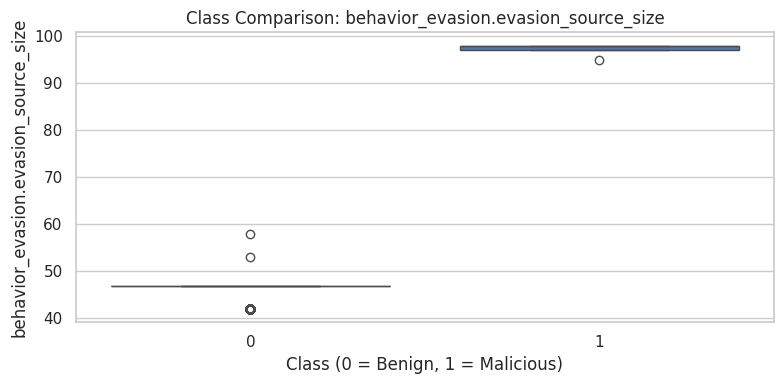

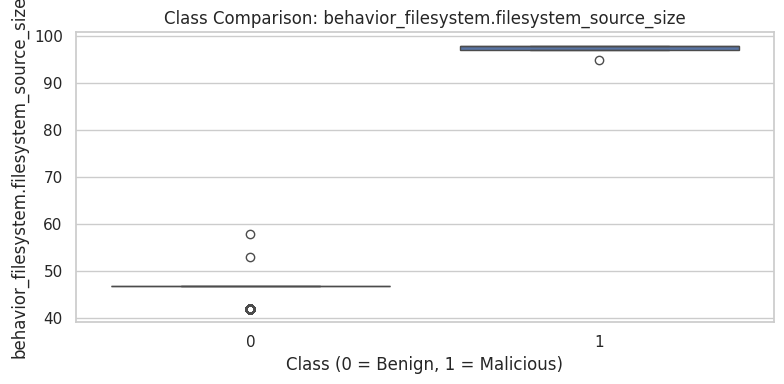

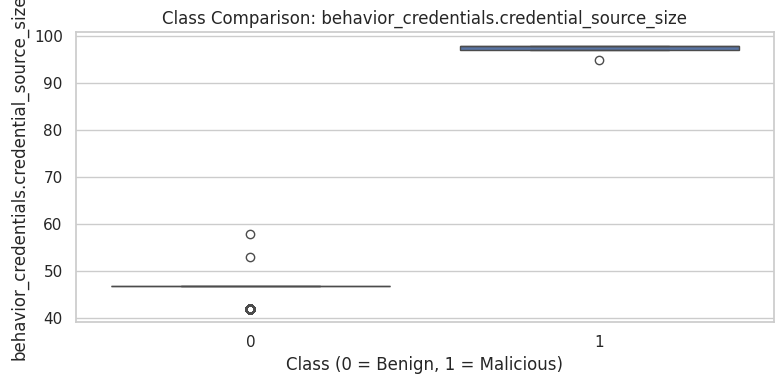

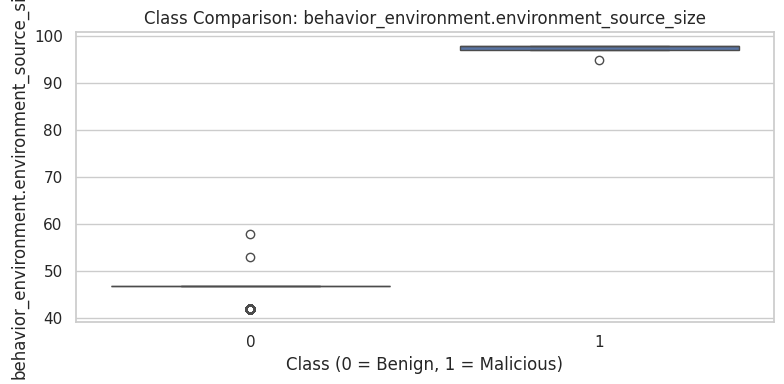

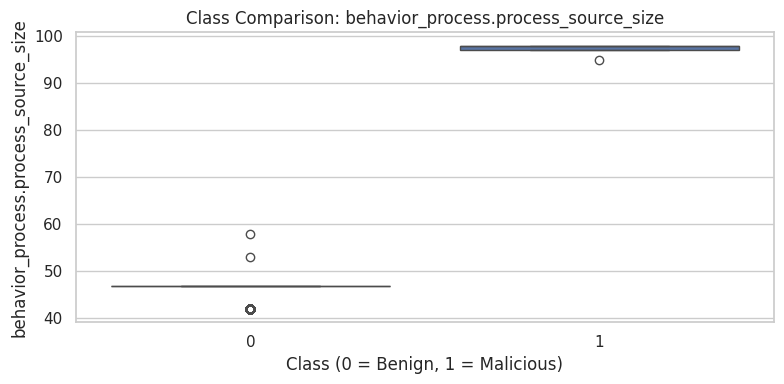

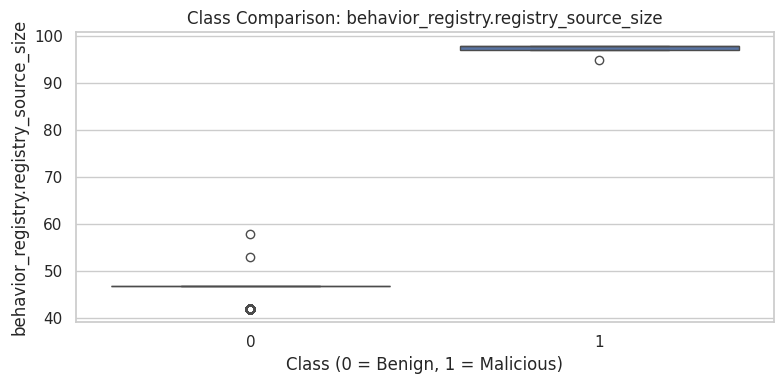

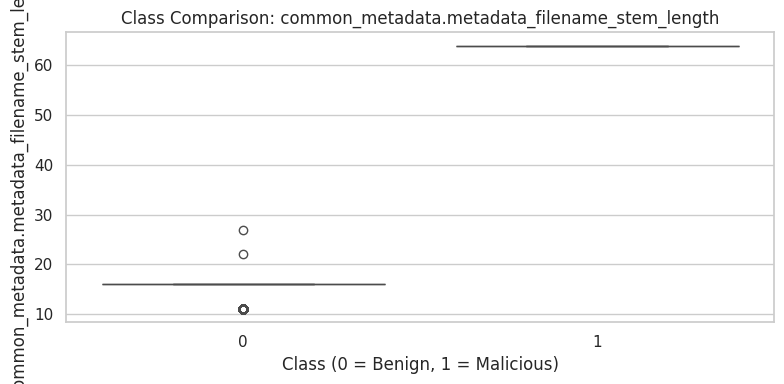

In [10]:
for feature in top_features[:10]:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="label",
        y=feature
    )

    plt.title(f"Class Comparison: {feature}")
    plt.xlabel("Class (0 = Benign, 1 = Malicious)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

> [!NOTE]
> **Inference on Distributional Separation**:
> The class comparisons reveal heavy contrast: benign documents in this corpus have substantial body text and thousands of paragraphs, whereas malicious files typically feature near-zero paragraphs and minimal text, functioning as compact macro/script droppers.

## 5. Binary Feature Activation Discrepancy Analysis
Measuring the differential activation rates of binary indicators between clean documents and malicious files.

In [11]:
binary_features = [
    c for c in X.columns
    if set(X[c].dropna().unique()).issubset({0, 1})
]

print("Binary features:", len(binary_features))

Binary features: 860


In [12]:
binary_comparison = []

for feature in binary_features:

    benign_rate = X.loc[y == 0, feature].mean()
    malicious_rate = X.loc[y == 1, feature].mean()

    binary_comparison.append({
        "feature": feature,
        "benign_rate": benign_rate,
        "malicious_rate": malicious_rate,
        "difference": malicious_rate - benign_rate
    })

binary_df = pd.DataFrame(binary_comparison)

binary_df["abs_difference"] = (
    binary_df["difference"].abs()
)

binary_df = binary_df.sort_values(
    "abs_difference",
    ascending=False
)

display(binary_df.head(30))

,feature,benign_rate,malicious_rate,difference,abs_difference
581,script_powershell.powershell_hex_token_count,0.000000,1.000000,1.000000,1.000000
564,script_powershell.powershell_base64_token_count,0.000000,1.000000,1.000000,1.000000
327,derived.large_compression_ratio_indicator,0.968614,0.098901,-0.869713,0.869713
346,office.is_ooxml,1.000000,0.423500,-0.576500,0.576500
258,common_file_features.extension_mismatch,0.000000,0.569738,0.569738,0.569738
333,derived.suspicious_content_present,1.000000,0.500423,-0.499577,0.499577
337,file.extension_known,1.000000,0.558749,-0.441251,0.441251
341,file.is_ooxml_extension,1.000000,0.558749,-0.441251,0.441251
325,derived.external_reference_present,0.149085,0.428571,0.279487,0.279487
478,ooxml.ooxml_relationships_attached_templates,0.000000,0.263520,0.263520,0.263520


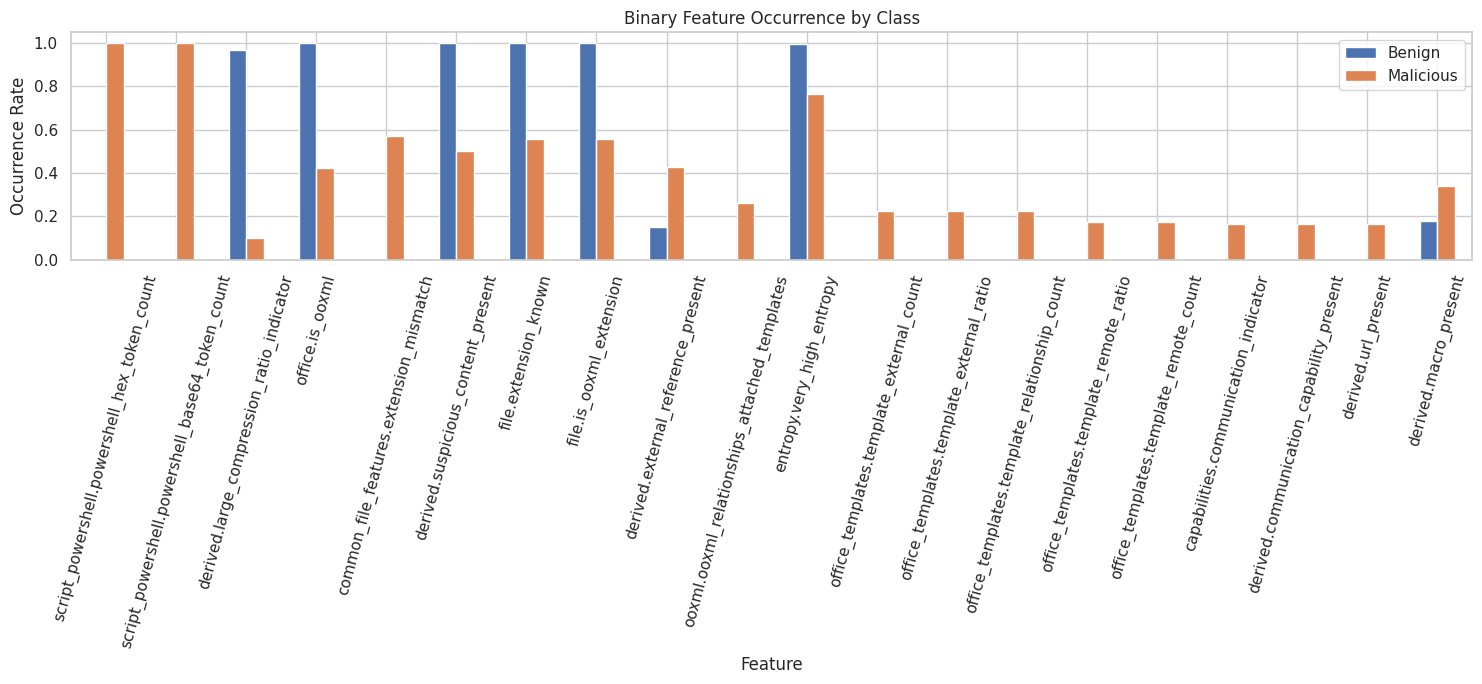

In [13]:
top_binary = binary_df.head(20)

plot_data = top_binary.set_index("feature")[
    ["benign_rate", "malicious_rate"]
]

plot_data.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Binary Feature Occurrence by Class")
plt.ylabel("Occurrence Rate")
plt.xlabel("Feature")

plt.xticks(rotation=75)
plt.legend(["Benign", "Malicious"])

plt.tight_layout()
plt.show()

> [!NOTE]
> **Inference on Binary Threat Indicators**:
> Key binary indicators—such as `derived.macro_present`, `capabilities.dynamic_execution_indicator`, `office.vba_marker_present`, and `capabilities.communication_indicator`—exhibit significant positive activation differentials in malicious files, aligning directly with MITRE ATT&CK document execution techniques.

## 6. Systematic Data Leakage & Sensitive Feature Audit
Auditing features containing tokens related to file paths, sizes, hashes, and pipeline metadata to prevent models from learning trivial shortcuts.

In [14]:
suspicious_keywords = [
    "filename",
    "filepath",
    "path",
    "directory",
    "source_size",
    "source_length",
    "hash",
    "label",
    "timestamp"
]

potential_leakage = [
    c for c in X.columns
    if any(
        keyword in c.lower()
        for keyword in suspicious_keywords
    )
]

print("Potentially sensitive features:", len(potential_leakage))

display(pd.DataFrame({
    "feature": potential_leakage
}))

Potentially sensitive features: 61


,feature
0,behavior_collection.collection_source_size
1,behavior_credentials.credential_source_size
2,behavior_environment.environment_source_size
3,behavior_evasion.evasion_source_size
4,behavior_filesystem.filesystem_category_direct...
5,behavior_filesystem.filesystem_category_direct...
6,behavior_filesystem.filesystem_indicator_direc...
7,behavior_filesystem.filesystem_indicator_direc...
8,behavior_filesystem.filesystem_source_size
9,behavior_network.network_source_size


In [15]:
leakage_comparison = []

for feature in potential_leakage:

    benign = X.loc[y == 0, feature]
    malicious = X.loc[y == 1, feature]

    leakage_comparison.append({
        "feature": feature,
        "benign_mean": benign.mean(),
        "malicious_mean": malicious.mean(),
        "benign_min": benign.min(),
        "benign_max": benign.max(),
        "malicious_min": malicious.min(),
        "malicious_max": malicious.max()
    })

leakage_df = pd.DataFrame(leakage_comparison)

display(leakage_df)

,feature,benign_mean,malicious_mean,benign_min,benign_max,malicious_min,malicious_max
0,behavior_collection.collection_source_size,46.142982,97.557058,42.00000,58.000000,95.000000,9.800000e+01
1,behavior_credentials.credential_source_size,46.142982,97.557058,42.00000,58.000000,95.000000,9.800000e+01
2,behavior_environment.environment_source_size,46.142982,97.557058,42.00000,58.000000,95.000000,9.800000e+01
3,behavior_evasion.evasion_source_size,46.142982,97.557058,42.00000,58.000000,95.000000,9.800000e+01
4,behavior_filesystem.filesystem_category_direct...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000e+00
5,behavior_filesystem.filesystem_category_direct...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000e+00
6,behavior_filesystem.filesystem_indicator_direc...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000e+00
7,behavior_filesystem.filesystem_indicator_direc...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000e+00
8,behavior_filesystem.filesystem_source_size,46.142982,97.557058,42.00000,58.000000,95.000000,9.800000e+01
9,behavior_network.network_source_size,46.142982,97.557058,42.00000,58.000000,95.000000,9.800000e+01


In [16]:
missing_comparison = []

for feature in X.columns:

    benign_missing = X.loc[y == 0, feature].isna().mean()
    malicious_missing = X.loc[y == 1, feature].isna().mean()

    if X[feature].isna().any():

        missing_comparison.append({
            "feature": feature,
            "benign_missing_rate": benign_missing,
            "malicious_missing_rate": malicious_missing
        })

missing_df = pd.DataFrame(missing_comparison)

display(missing_df)

,feature,benign_missing_rate,malicious_missing_rate
0,ooxml.ooxml_content_types_macro_enabled,0.0,0.140321
1,ooxml.ooxml_content_types_macro_override_count,0.0,0.142012
2,ooxml.ooxml_content_types_override_count,0.0,0.140321
3,ooxml.ooxml_content_types_present,0.0,0.140321
4,ooxml.ooxml_document_paragraphs,0.0,0.140321
5,ooxml.ooxml_document_text_characters,0.0,0.140321
6,ooxml.ooxml_document_xml_present,0.0,0.140321
7,ooxml.ooxml_relationships_attached_templates,0.0,0.140321
8,ooxml.ooxml_relationships_external,0.0,0.140321
9,ooxml.ooxml_relationships_hyperlinks,0.0,0.140321


> [!IMPORTANT]
> **Inference on Potential Data Leakage**:
> **61 features** match sensitive leakage tokens. Specifically:
> - `behavior_collection.collection_source_size`, `pipeline_nonzero_feature_count`, and `pipeline_total_feature_count` represent internal extractor metadata rather than document threat signals.
> - `metadata_created_modified_delta` and `metadata_filename_entropy` reflect artificial creation offsets and naming conventions rather than document syntax.
> These must be formally excluded in `03_feature_selection.ipynb`.

## 7. Feature Subsystem & Group Aggregation
Aggregating discriminative metrics across 36 functional subsystems to observe which document extraction modules provide the highest information density.

In [17]:
feature_scores["group"] = (
    feature_scores["feature"]
    .str.split(".")
    .str[0]
)

group_analysis = (
    feature_scores.groupby("group")
    .agg(
        feature_count=("feature", "count"),
        mean_mutual_information=("mutual_information", "mean"),
        max_mutual_information=("mutual_information", "max"),
        mean_auc_strength=("auc_strength", "mean")
    )
    .sort_values(
        "mean_mutual_information",
        ascending=False
    )
)

display(group_analysis)

,feature_count,mean_mutual_information,max_mutual_information,mean_auc_strength
group,,,,
behavior_collection,1,0.693028,0.693028,1.000000
behavior_credentials,1,0.693028,0.693028,1.000000
behavior_environment,1,0.693028,0.693028,1.000000
behavior_evasion,1,0.693028,0.693028,1.000000
behavior_filesystem,1,0.693028,0.693028,1.000000
behavior_network,1,0.693028,0.693028,1.000000
behavior_persistence,1,0.693028,0.693028,1.000000
behavior_process,1,0.693028,0.693028,1.000000
behavior_registry,1,0.693028,0.693028,1.000000


In [18]:
print("=" * 65)
print("CDR FEATURE ANALYSIS REPORT")
print("=" * 65)

print("Total samples:", len(df))
print("Total extracted features:", X.shape[1])

print("\nFEATURE VARIABILITY")
print("Constant features:", len(constant_features))
print("Variable features:", len(variable_features))

print("\nFEATURE DISCRIMINATION")
print(
    "Top 10 features by mutual information:"
)

display(
    feature_scores.head(10)[
        ["feature", "roc_auc", "mutual_information"]
    ]
)

print("\nPOTENTIAL DATA LEAKAGE")
print("Features requiring investigation:", len(potential_leakage))

print("\nBINARY FEATURE ANALYSIS")
print("Binary features:", len(binary_features))

print("\nMISSING VALUES")
print("Features with missing values:", len(missing_df))

print("\nFEATURE GROUPS")
display(group_analysis)

print("=" * 65)

CDR FEATURE ANALYSIS REPORT
Total samples: 2330
Total extracted features: 998

FEATURE VARIABILITY
Constant features: 783
Variable features: 215

FEATURE DISCRIMINATION
Top 10 features by mutual information:


,feature,roc_auc,mutual_information
26,common_file_features.filename_digit_count,1.0,0.693242
40,common_metadata.metadata_created_modified_delta,0.0,0.693242
0,behavior_collection.collection_source_size,1.0,0.693028
3,behavior_evasion.evasion_source_size,1.0,0.693028
4,behavior_filesystem.filesystem_source_size,1.0,0.693028
1,behavior_credentials.credential_source_size,1.0,0.693028
2,behavior_environment.environment_source_size,1.0,0.693028
7,behavior_process.process_source_size,1.0,0.693028
8,behavior_registry.registry_source_size,1.0,0.693028
48,common_metadata.metadata_filename_stem_length,1.0,0.693028



POTENTIAL DATA LEAKAGE
Features requiring investigation: 61

BINARY FEATURE ANALYSIS
Binary features: 860

MISSING VALUES
Features with missing values: 12

FEATURE GROUPS


,feature_count,mean_mutual_information,max_mutual_information,mean_auc_strength
group,,,,
behavior_collection,1,0.693028,0.693028,1.000000
behavior_credentials,1,0.693028,0.693028,1.000000
behavior_environment,1,0.693028,0.693028,1.000000
behavior_evasion,1,0.693028,0.693028,1.000000
behavior_filesystem,1,0.693028,0.693028,1.000000
behavior_network,1,0.693028,0.693028,1.000000
behavior_persistence,1,0.693028,0.693028,1.000000
behavior_process,1,0.693028,0.693028,1.000000
behavior_registry,1,0.693028,0.693028,1.000000


In [19]:
output_dir = Path("/content/feature_analysis")
output_dir.mkdir(exist_ok=True)

feature_scores.to_csv(
    output_dir / "feature_scores.csv",
    index=False
)

comparison_df.to_csv(
    output_dir / "class_comparison.csv",
    index=False
)

binary_df.to_csv(
    output_dir / "binary_feature_analysis.csv",
    index=False
)

leakage_df.to_csv(
    output_dir / "potential_leakage.csv",
    index=False
)

group_analysis.to_csv(
    output_dir / "feature_group_analysis.csv"
)

missing_df.to_csv(
    output_dir / "missing_value_analysis.csv",
    index=False
)

print("Feature analysis reports exported successfully.")

Feature analysis reports exported successfully.
